In [1]:
# Importing necessary packages and functions required
import numpy as np # for numerical computations
import pandas as pd # for data processing,I/O file operations
import matplotlib.pyplot as plt # for visualization of different kinds of plots
%matplotlib inline
# for matplotlib graphs to be included in the notebook, next to the code
import seaborn as sns # for visualization
import warnings # to silence warnings
warnings.filterwarnings('ignore')

In [3]:
# Reading the dataset
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data'
crime = pd.read_csv(url, header=None, na_values=['?'])
crime.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [5]:
# examing the response variable
crime[127].describe()

count    1994.000000
mean        0.237979
std         0.232985
min         0.000000
25%         0.070000
50%         0.150000
75%         0.330000
max         1.000000
Name: 127, dtype: float64

<Axes: >

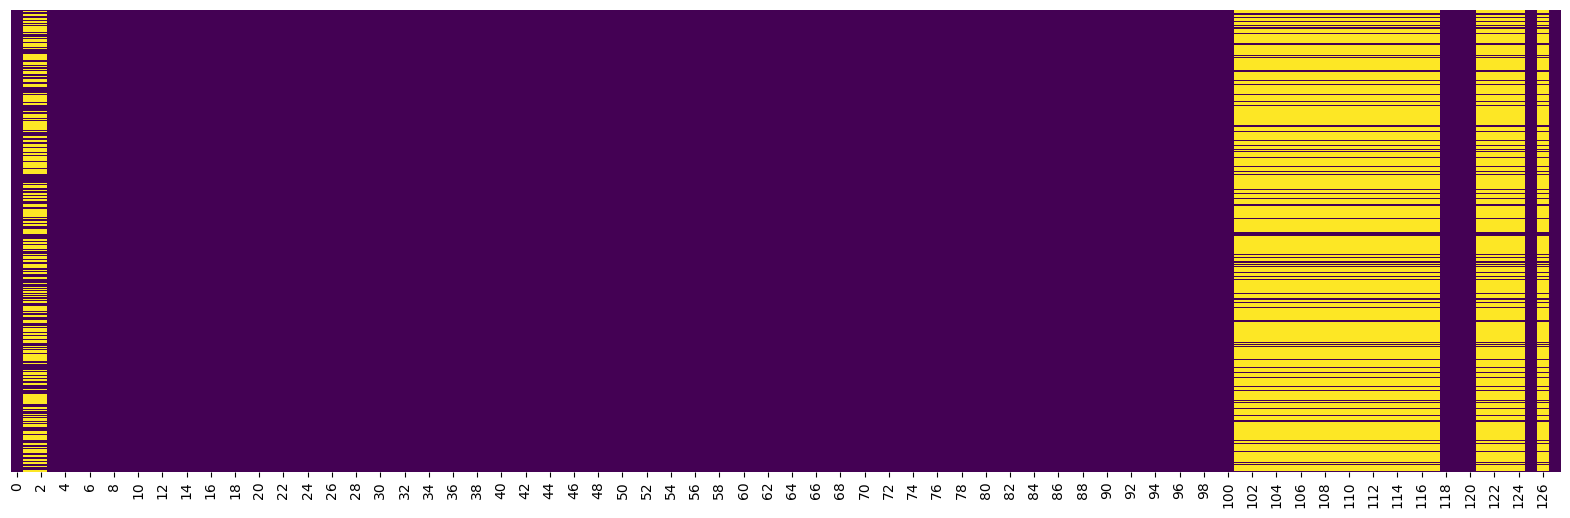

In [7]:
plt.figure(figsize=(20, 6))
sns.heatmap(crime.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [9]:
# remove categorical features
crime.drop([0, 1, 2, 3, 4], axis=1, inplace=True)

In [11]:
# remove rows with any missing values
crime.dropna(inplace=True)

<Axes: >

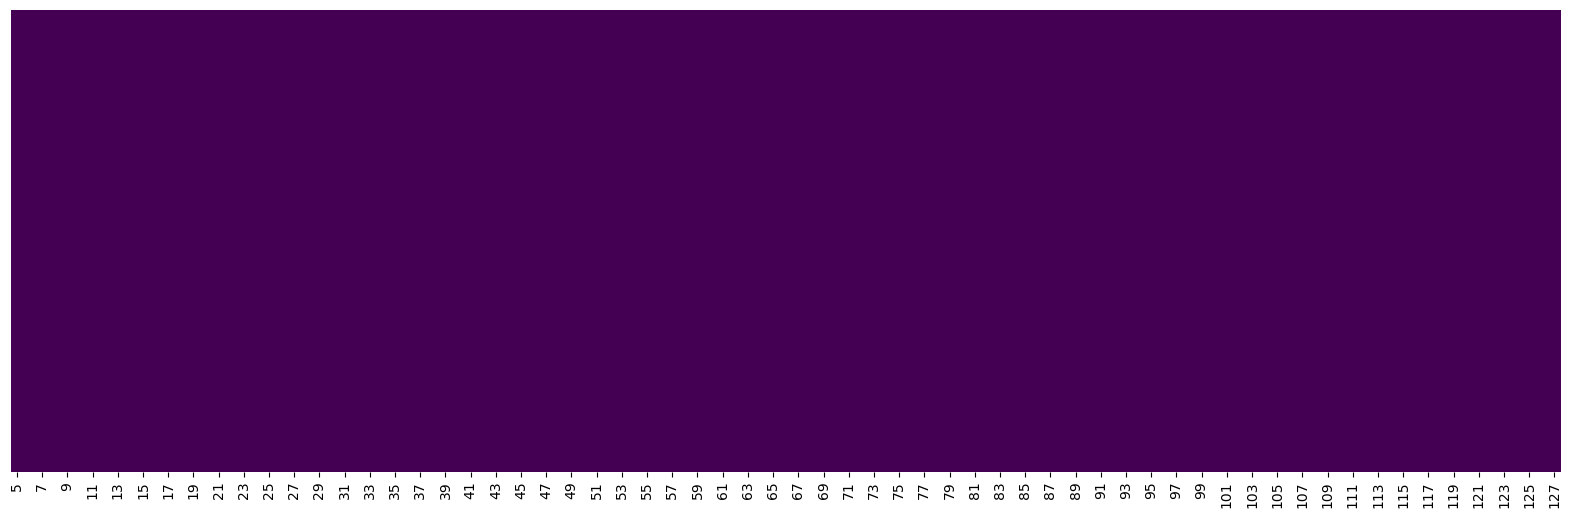

In [13]:
plt.figure(figsize=(20, 6)) 
sns.heatmap(crime.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [15]:
# checking the shape 
crime.shape

(319, 123)

In [17]:
crime.head()

,5,6,7,8,9,10,11,12,13,14,...,118,119,120,121,122,123,124,125,126,127
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
16,0.15,0.31,0.40,0.63,0.14,0.06,0.58,0.72,0.65,0.47,...,0.06,0.39,0.84,0.06,0.06,0.91,0.5,0.88,0.26,0.49
20,0.25,0.54,0.05,0.71,0.48,0.30,0.42,0.48,0.28,0.32,...,0.09,0.46,0.05,0.09,0.05,0.88,0.5,0.76,0.13,0.34
21,1.00,0.42,0.47,0.59,0.12,0.05,0.41,0.53,0.34,0.33,...,1.00,0.07,0.15,1.00,0.35,0.73,0.0,0.31,0.21,0.69
23,0.11,0.43,0.04,0.89,0.09,0.06,0.45,0.48,0.31,0.46,...,0.16,0.12,0.07,0.04,0.01,0.81,1.0,0.56,0.09,0.63


In [19]:
# define X and y 
X = crime.drop(127, axis=1) 
y = crime[127]

In [21]:
# split into training and testing sets 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size = 0.3,random_state=1)

LinearRegression

In [23]:
# build a linear regression model
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

LinearRegression()

In [25]:
print ("INTERCEPT : ",linreg.intercept_) 
print ("CO-EFFICIENT : ",linreg.coef_)

INTERCEPT :  0.9922125287583787
CO-EFFICIENT :  [-3.93018330e+00  7.31324716e-01 -3.01181421e-01 -2.96634778e-01
 -1.83170801e-01  2.81575284e-01 -1.48744636e+00 -4.84695533e-01
  1.24104896e+00 -5.32282788e-01  4.64331123e+00 -1.17079618e-01
  1.04229108e+00  1.36950901e-01 -3.12434116e-01 -1.16489196e+00
  5.37252913e-01  7.49655606e-01 -8.02500871e-02  8.42449509e-01
 -1.98951720e-01 -3.17193999e-01 -4.31217869e-01  1.19357660e-01
 -1.83148129e-01  2.11602690e-01 -1.57441950e-01 -1.03051105e+00
  1.49628176e+00  1.86093900e-01 -1.12289917e+00 -1.13107576e-02
  1.22670519e-01  1.46348876e-01 -1.64172731e-01 -3.73690589e-02
  1.92733806e-01  4.34808503e-01  2.32870361e+00 -5.15176228e-01
  2.64683754e+00 -5.48075999e+00  9.63873430e-01 -1.15021921e+00
 -1.15575665e+00  1.10543276e+00  2.41469970e-01 -6.32209680e-01
  6.01741978e-01  8.37645340e-02  1.05006759e-01 -2.58807800e-01
  5.31513493e-01 -8.57090632e-01 -3.29684470e-01  6.61114510e-01
 -5.61884511e-01  6.27806334e-01  2.798480

In [27]:
# make predictions
y_pred = linreg.predict(X_test)

In [29]:
# calculate R^2 value, MAE, MSE, RMSE
from sklearn.metrics import r2_score
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.19704456295409112
mean_absolute_error : 0.16725155824888352
mean_squared_error :  0.049863454226934036
root_mean_squared_error :  0.22330126337961914


Ridge regression
* Documentación de Ridge
* alpha: debe ser positivo, aumentar para una mayor regularización
* normalizar: escala las características (sin usar StandardScaler)

In [31]:
# alpha=0 is equivalent to linear regression
from sklearn.linear_model import Ridge
ridgereg = Ridge(alpha=0)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.1970445629542279
mean_absolute_error : 0.16725155824888996
mean_squared_error :  0.04986345422692554
root_mean_squared_error :  0.22330126337960013


In [33]:
# try alpha=0.1
ridgereg = Ridge(alpha=0.1)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.5262899491498707
mean_absolute_error : 0.12670910679284855
mean_squared_error :  0.029417347897045868
root_mean_squared_error :  0.1715148620296383


In [35]:
# examing the coefficients
print(ridgereg.coef_)

[ 0.05387341  0.08777086 -0.07857429 -0.06655408 -0.06702733  0.13302291
 -0.1370288  -0.09679891  0.04005784  0.10895944  0.14510316 -0.0607175
  0.24718976 -0.14383986 -0.16294646 -0.7013852  -0.08493163  0.25651168
 -0.0640989   0.31370894 -0.16763968 -0.01301493 -0.21263312 -0.03834742
 -0.04809351  0.18745164 -0.00624572 -0.45494164  0.42996759 -0.15264878
 -0.34532288  0.01863149  0.23713783  0.07415328 -0.19601847  0.05728627
  0.21630242  0.07246309  0.10444008  0.02840552 -0.24635709 -0.14606914
  0.21525031 -0.30256506 -0.28703885  0.14805249 -0.03272993 -0.21056436
  0.26965804 -0.03832653  0.25220687 -0.13023572  0.09021605 -0.33033235
  0.16968566  0.05538314 -0.07564988  0.01935623  0.15338743 -0.20692943
  0.12604865  0.16218614 -0.04463706 -0.15395487 -0.02984134  0.05967376
 -0.33486134  0.02951153  0.13938822  0.41776989  0.04696951  0.11288745
  0.13816489  0.17877385 -0.04233009  0.08900267 -0.01499668  0.04060738
 -0.1509511  -0.08987278 -0.08621681  0.03927102 -0.

* RidgeCV: ridge regression con validación cruzada incorporada del parámetro alfa (LO VER
EMOS EN UN SIGUIENTE NOTEBOOK
* • alfas: matriz de valores alfa para probar

In [37]:
# create an array of alpha values
alpha_range = 10.**np.arange(-2, 3)
alpha_range

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [39]:
# select the best alpha with RidgeCV
from sklearn.linear_model import RidgeCV
ridgeregcv = RidgeCV(alphas=alpha_range,scoring='neg_mean_squared_error')
ridgeregcv.fit(X_train, y_train)
ridgeregcv.alpha_

10.0

In [41]:
# predict method uses the best alpha value
y_pred = ridgeregcv.predict(X_test)
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.5442422344114474
mean_absolute_error : 0.13277523657131698
mean_squared_error :  0.02830251273545482
root_mean_squared_error :  0.16823350657777666


In [43]:
# Generar 200 valores de alpha
n_alphas = 200
alphas = np.logspace(-10, -2, n_alphas)
# Calcular los coeficientes para cada alpha
from sklearn.linear_model import Ridge, RidgeCV

coefs = []
for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train, y_train)
    coefs.append(ridge.coef_)


# Seleccionar el mejor alpha mediante validación cruzada
ridgeregcv_trayectoria = RidgeCV(
    alphas=alphas,
    scoring='neg_mean_squared_error',
    cv=5
)
ridgeregcv_trayectoria.fit(X_train, y_train)

# Mostrar el mejor alpha
print("Mejor alpha:", ridgeregcv_trayectoria.alpha_)
# Examinar los coeficientes
print("Coeficientes:", ridgeregcv_trayectoria.coef_)
# Predicciones Ridge
y_pred_ridge = ridgeregcv_trayectoria.predict(X_test)
print("RESULTADOS RIDGE")
print("R-Square:", r2_score(y_test, y_pred_ridge))
print("MAE:", metrics.mean_absolute_error(y_test, y_pred_ridge))
print("MSE:", metrics.mean_squared_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_pred_ridge)))

Mejor alpha: 0.01
Coeficientes: [-2.24331356e-01  4.13190973e-01 -2.59158536e-01 -1.42281589e-01
 -1.31646207e-01  1.90968380e-01 -6.91941241e-01 -3.66752297e-01
  5.46789658e-01 -5.30474654e-02  6.86573040e-01 -6.96665949e-02
  7.18381686e-01 -9.07644996e-02 -1.90473226e-01 -1.03942442e+00
  2.44200317e-02  5.02785197e-01  1.27551634e-01  7.03754166e-01
 -4.64766257e-01 -3.25041891e-02 -3.60054262e-01  7.92111941e-02
 -1.28636632e-01  2.42289262e-01 -1.41085766e-01 -9.03656330e-01
  1.11647210e+00 -2.19467596e-02 -7.41205298e-01  7.71418997e-02
  2.61096106e-01  3.72187192e-01 -2.08270005e-01  1.12135779e-02
  3.29599972e-01  2.54748597e-01  3.96107078e-01 -1.90160626e-01
 -2.96957609e-01 -7.59043963e-01  6.38681415e-01 -7.06028162e-01
 -8.25981518e-01  6.89517468e-01  2.59748305e-02 -5.26622981e-01
  5.40854547e-01  9.35623236e-02  1.74007850e-01 -1.84010614e-01
  3.18950924e-01 -7.38499885e-01  2.79503158e-01  1.47333460e-01
 -2.34915201e-01  4.07967499e-01  6.31569193e-01 -1.220600

#  Lasso regression
* Documentación de Lasso
* aalpha  deb ese rpositivo ,aumenta rpar au namayo rregularizació
* n•normalizar: esca lal ascaracterístic as(sinusarStandardScaler)

In [45]:
 #tryalpha=0.001andexaminecoefficients
from sklearn.linear_model import Lasso
lassoreg= Lasso(alpha=0.001)
lassoreg.fit(X_train,y_train)
print(lassoreg.coef_)

[-0.         -0.          0.02952448 -0.1287308   0.          0.00397093
 -0.         -0.         -0.          0.         -0.          0.
 -0.         -0.03506582 -0.02065343 -0.19306594  0.          0.0087343
 -0.          0.          0.          0.         -0.         -0.05959218
  0.          0.01419686  0.         -0.08367502  0.         -0.
 -0.         -0.          0.1588383  -0.         -0.10618712  0.
  0.         -0.          0.06905018  0.          0.          0.
  0.         -0.13432462 -0.17544062 -0.         -0.         -0.
 -0.         -0.          0.14102046 -0.         -0.         -0.
 -0.         -0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.          0.
 -0.          0.          0.          0.0895257  -0.          0.
 -0.          0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.         -0.09238764 -0.
 -0.         -0.         -0.         -0.         -0.06494622  0.032

In [47]:
 #tryalpha=0.01andexaminecoefficients
lassoreg= Lasso(alpha=0.01)
lassoreg.fit(X_train,y_train)
print(lassoreg.coef_)

[ 0.         -0.          0.03599774 -0.23321176  0.          0.
  0.          0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.          0.          0.004772
 -0.         -0.         -0.         -0.         -0.         -0.
 -0.         -0.         -0.          0.          0.08100163  0.
  0.         -0.          0.         -0.         -0.          0.
  0.         -0.          0.          0.          0.          0.
  0.         -0.         -0.14312013 -0.07280454 -0.         -0.
 -0.          0.          0.19728557  0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.         -0.
  0.         -0.          0.          0.         -0.          0.01620678
 -0.         -0.          0.00075449  0.          0.          0.
  0.         -0.         -0.         -0.         -0.         -0.
 -0.         -0.          0.         -0.         -0.          0.
  0.1096124

In [49]:
 # calculate RMSE (for alpha=0.01)
y_pred = lassoreg.predict(X_test)
# calculate MAE, MSE, RMSE
# calculate R^2 value, MAE, MSE, RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))

print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-Square Value 0.549435901066182
mean_absolute_error : 0.13629414371437606
mean_squared_error :  0.027979986543389807
root_mean_squared_error :  0.16727219297716464


In [51]:
# select the best alpha with LassoCV
from sklearn.linear_model import LassoCV
lassoregcv = LassoCV(n_alphas=100, random_state=1)
lassoregcv.fit(X_train, y_train)
print('alpha : ',lassoregcv.alpha_)
#examine thecoefficients
print(lassoregcv.coef_)

alpha :  0.0029564957162874243
[ 0.         -0.          0.05482897 -0.21590313 -0.          0.
  0.         -0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.0398597   0.          0.03838033
 -0.         -0.         -0.         -0.         -0.         -0.
 -0.          0.         -0.          0.          0.13216579  0.
  0.         -0.          0.02523867 -0.         -0.          0.
  0.         -0.          0.11986949  0.          0.          0.
  0.         -0.02528178 -0.2950619  -0.         -0.         -0.
 -0.         -0.          0.08750744  0.         -0.         -0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.         -0.
 -0.         -0.          0.00949807  0.         -0.          0.
 -0.         -0.          0.          0.          0.          0.
  0.         -0.         -0.         -0.         -0.01256026 -0.
 -0.         -0.          0.         -0.         -0

In [55]:
#predict method usesthebestalphavalue
y_pred =lassoregcv.predict(X_test)
#calculate R^2 value,MAE,MSE,RMSE
from sklearn import metrics
print("R-SquareValue",r2_score(y_test,y_pred))
print ("mean_absolute_error:",metrics.mean_absolute_error(y_test,y_pred))
print ("mean_squared_error: ",metrics.mean_squared_error(y_test,y_pred))
print ("root_mean_squared_error:",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

R-SquareValue 0.5439920815003265
mean_absolute_error: 0.13445102835805997
mean_squared_error:  0.028318047206806432
root_mean_squared_error: 0.16827966961818777
